# Module 8: Derivatives: Option Pricing, Greeks and Hedging

**Business question:** NovaFin has exposure to equity options. Can ML improve option pricing, and how should the exposure be managed?

**Chain:** option contract data → Black-Scholes price (theory) and ML price → pricing error vs market → Greeks of the book → hedge → risk decision.

**What you will learn:** the Black-Scholes formula, implied volatility and the "smile", ML as a correction on top of theory (residual learning), the Greeks, and delta hedging.

## 0. Setup

In [1]:
import warnings; warnings.filterwarnings("ignore")
import sys, subprocess, importlib.util
if importlib.util.find_spec("google.colab"):             # Colab: install the extra libraries once
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "shap", "xgboost", "lightgbm", "imbalanced-learn"])
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import norm
try:
    from google.colab import drive; drive.mount("/content/drive")
except ImportError:
    pass
CANDIDATES = [Path("/content/drive/MyDrive/NovaFin_Capstone/data"), Path("../../Project"), Path("/mnt/project-files/Project")]
DATA = next(p for p in CANDIDATES if (p / "nova_options.csv").exists())
OUT = DATA.parent / "outputs" if "drive" in str(DATA) else Path("../outputs")
OUT.mkdir(exist_ok=True, parents=True)
SEED = 42
sns.set_theme(style="whitegrid", palette="deep")

## 1. Load and inspect

In [2]:
df = pd.read_csv(DATA / "nova_options.csv")
df["Is_Call"] = (df.Option_Type == "Call").astype(int)
df["Moneyness"] = df.Spot / df.Strike
print(df.shape, "| missing:", df.isna().sum().sum())
print(df.Option_Type.value_counts().to_dict(), "| underlyings:", df.Underlying.nunique())
df.describe().T.round(3)

(10000, 13) | missing: 0
{'Put': 5055, 'Call': 4945} | underlyings: 15


,count,mean,std,min,25%,50%,75%,max
Option_ID,10000.0,7005000.500,2886.896,7000001.000,7002500.750,7005000.500,7007500.250,7010000.000
Strike,10000.0,1793.109,1024.121,78.350,927.642,1753.065,2591.575,4348.870
Spot,10000.0,1793.747,981.004,100.590,952.722,1787.605,2642.292,3499.600
Time_to_Maturity,10000.0,1.011,0.567,0.030,0.530,1.000,1.502,2.000
Volatility,10000.0,0.240,0.078,0.080,0.186,0.239,0.292,0.536
Interest_Rate,10000.0,0.065,0.008,0.034,0.060,0.065,0.070,0.099
Black_Scholes_Price,10000.0,193.901,203.340,0.000,36.805,123.620,290.850,1188.230
Market_Price,10000.0,193.954,203.649,0.010,36.788,123.620,289.812,1245.560
Is_Call,10000.0,0.494,0.500,0.000,0.000,0.000,1.000,1.000
Moneyness,10000.0,1.023,0.150,0.800,0.892,1.003,1.142,1.333


## 2. Task 1: Black-Scholes benchmark
For a European option with spot S, strike K, time T (years), rate r and volatility σ:

$$d_1 = \frac{\ln(S/K) + (r + \sigma^2/2)T}{\sigma\sqrt{T}}, \quad d_2 = d_1 - \sigma\sqrt{T}$$
$$C = S\,N(d_1) - K e^{-rT} N(d_2), \qquad P = K e^{-rT} N(-d_2) - S\,N(-d_1)$$

In [3]:
def bs_price(S, K, T, r, sig, call):
    d1 = (np.log(S / K) + (r + 0.5 * sig ** 2) * T) / (sig * np.sqrt(T)); d2 = d1 - sig * np.sqrt(T)
    c = S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    p = K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)
    return np.where(call, c, p)

df["BS_ours"] = bs_price(df.Spot, df.Strike, df.Time_to_Maturity, df.Interest_Rate, df.Volatility, df.Is_Call == 1)
print("Max |our BS − file BS|:", round((df.BS_ours - df.Black_Scholes_Price).abs().max(), 4), "(rounding only)")

Max |our BS − file BS|: 0.2657 (rounding only)


Black-Scholes vs market:
RMSE                  9.812
MAE                   5.842
Mean error            0.052
MAPE % (price>₹10)    4.014
dtype: float64


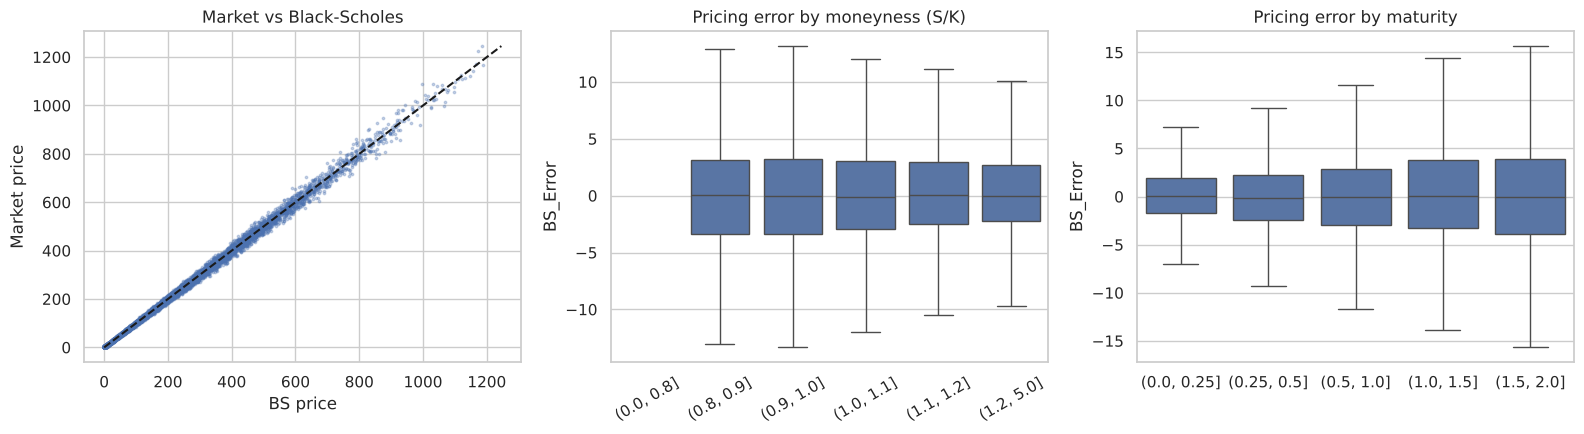

In [4]:
df["BS_Error"] = df.Market_Price - df.Black_Scholes_Price
def err(y, yhat):
    return pd.Series({"RMSE": np.sqrt(((y - yhat) ** 2).mean()), "MAE": (y - yhat).abs().mean(), "Mean error": (y - yhat).mean(),
                      "MAPE % (price>₹10)": ((y - yhat).abs() / y)[y > 10].mean() * 100})
print("Black-Scholes vs market:"); print(err(df.Market_Price, df.Black_Scholes_Price).round(3))
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].scatter(df.Black_Scholes_Price, df.Market_Price, s=3, alpha=0.3); ax[0].plot([0, df.Market_Price.max()], [0, df.Market_Price.max()], "k--"); ax[0].set(title="Market vs Black-Scholes", xlabel="BS price", ylabel="Market price")
sns.boxplot(x=pd.cut(df.Moneyness, [0, 0.8, 0.9, 1.0, 1.1, 1.2, 5]), y=df.BS_Error, ax=ax[1], showfliers=False).set(title="Pricing error by moneyness (S/K)", xlabel="")
ax[1].tick_params(axis="x", rotation=30)
sns.boxplot(x=pd.cut(df.Time_to_Maturity, [0, 0.25, 0.5, 1, 1.5, 2]), y=df.BS_Error, ax=ax[2], showfliers=False).set(title="Pricing error by maturity", xlabel="")
plt.tight_layout(); plt.show()

### Implied volatility and the "smile"
Implied volatility is the σ that makes Black-Scholes equal the market price. If the market priced options exactly like Black-Scholes, implied vol would equal the input `Volatility` everywhere. A pattern across moneyness (a "smile" or "skew") would be something ML could learn.

In [5]:
def implied_vol(price, S, K, T, r, call, lo=1e-4, hi=3.0, n=80):
    lo, hi = np.full(len(price), lo), np.full(len(price), hi)
    for _ in range(n):                       # vectorised bisection
        mid = (lo + hi) / 2
        too_high = bs_price(S, K, T, r, mid, call) > price
        hi, lo = np.where(too_high, mid, hi), np.where(too_high, lo, mid)
    return (lo + hi) / 2
intrinsic = np.where(df.Is_Call == 1, df.Spot - df.Strike * np.exp(-df.Interest_Rate * df.Time_to_Maturity), df.Strike * np.exp(-df.Interest_Rate * df.Time_to_Maturity) - df.Spot).clip(0)
ok = df.Market_Price > intrinsic + 0.01
df.loc[ok, "Implied_Vol"] = implied_vol(df.Market_Price[ok].values, df.Spot[ok].values, df.Strike[ok].values, df.Time_to_Maturity[ok].values, df.Interest_Rate[ok].values, (df.Is_Call[ok] == 1).values)
df["IV_minus_Vol"] = df.Implied_Vol - df.Volatility
smile = df.groupby(pd.cut(df.Moneyness, [0, 0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 5]), observed=True).IV_minus_Vol.agg(["mean", "std", "count"]).round(4)
smile

,mean,std,count
Moneyness,,,
"(0.8, 0.9]",0.0043,0.0338,2587
"(0.9, 1.0]",0.0006,0.0195,2216
"(1.0, 1.1]",0.0006,0.0196,1843
"(1.1, 1.2]",0.0069,0.0375,1400
"(1.2, 1.3]",0.0204,0.0719,1044
"(1.3, 5.0]",0.0328,0.0932,316


**What we see:** the implied-minus-input volatility gap averages about zero in every moneyness bucket. There is no systematic smile: the market deviations from Black-Scholes look like random noise. That already tells us ML has little to learn here.

## 3. Task 2: ML pricing
Two approaches:
1. **Direct:** predict Market_Price from contract features.
2. **Residual (hybrid):** predict the *error* Market − BS and add it back to BS. Theory does the heavy lifting; ML only learns corrections.

Features: moneyness, log-moneyness, time to maturity, volatility, rate, call/put, underlying, and the BS price itself (for the residual model). 80/20 random split. Contracts are independent, so a random split is fine here.

In [6]:
from sklearn.model_selection import train_test_split
from lightgbm import LGBMRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

F = pd.DataFrame({"Moneyness": df.Moneyness, "Log_Moneyness": np.log(df.Moneyness), "T": df.Time_to_Maturity, "Vol": df.Volatility,
                  "r": df.Interest_Rate, "Is_Call": df.Is_Call, "Vol_sqrtT": df.Volatility * np.sqrt(df.Time_to_Maturity),
                  "BS_over_K": df.Black_Scholes_Price / df.Strike})
F = pd.concat([F, pd.get_dummies(df.Underlying, prefix="U", dtype=float)], axis=1)
idx_tr, idx_te = train_test_split(df.index, test_size=0.2, random_state=SEED)
K_te = df.Strike[idx_te]

out = {"Black-Scholes": err(df.Market_Price[idx_te], df.Black_Scholes_Price[idx_te])}
# Direct models learn price / strike (scale-free), then multiply back by strike
y_direct = df.Market_Price / df.Strike
direct_models = {"Direct LightGBM": LGBMRegressor(n_estimators=600, learning_rate=0.03, num_leaves=31, random_state=SEED, verbose=-1),
                 "Direct neural net": make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(64, 64), max_iter=400, early_stopping=True, random_state=SEED))}
Fd = F.drop(columns="BS_over_K")
preds = {}
for name, m in direct_models.items():
    m.fit(Fd.loc[idx_tr], y_direct[idx_tr]); preds[name] = m.predict(Fd.loc[idx_te]) * K_te
    out[name] = err(df.Market_Price[idx_te], preds[name])
# Residual model learns (market − BS) / strike
y_res = df.BS_Error / df.Strike
res_m = LGBMRegressor(n_estimators=300, learning_rate=0.02, num_leaves=15, min_child_samples=50, random_state=SEED, verbose=-1).fit(F.loc[idx_tr], y_res[idx_tr])
preds["Hybrid BS + LightGBM residual"] = df.Black_Scholes_Price[idx_te] + res_m.predict(F.loc[idx_te]) * K_te
out["Hybrid BS + LightGBM residual"] = err(df.Market_Price[idx_te], preds["Hybrid BS + LightGBM residual"])
comparison = pd.DataFrame(out).T.round(3)
comparison

,RMSE,MAE,Mean error,MAPE % (price>₹10)
Black-Scholes,10.147,6.073,-0.049,4.085
Direct LightGBM,13.645,8.478,0.158,6.199
Direct neural net,21.902,14.457,1.357,14.072
Hybrid BS + LightGBM residual,10.391,6.168,-0.017,4.208


In [7]:
by_m = pd.DataFrame({name: (df.Market_Price[idx_te] - (df.Black_Scholes_Price[idx_te] if name == "Black-Scholes" else preds[name])).abs()
                     .groupby(pd.cut(df.Moneyness[idx_te], [0, 0.9, 1.1, 5], labels=["OTM-ish (<0.9)", "Near ATM", ">1.1"])).mean()
                     for name in comparison.index}).round(3)
by_m.T

Moneyness,OTM-ish (<0.9),Near ATM,>1.1
Black-Scholes,6.096,5.616,6.616
Direct LightGBM,8.821,8.070,8.690
Direct neural net,16.353,13.261,14.330
Hybrid BS + LightGBM residual,6.043,5.646,6.916


**Reading the comparison:** a pure ML model has to re-learn option theory from 8,000 examples, and it ends up *worse* than Black-Scholes. The hybrid model is about as good as Black-Scholes and cannot beat it meaningfully, because the remaining market error has no learnable pattern (as the implied-vol check showed). **Black-Scholes remains the pricing model of record**; ML is useful only as a monitoring tool to flag contracts whose market price drifts unusually far from theory.

## 4. Greeks of the options book
Assume NovaFin is **long one contract (lot of 1) of every option** in the file. The Greeks measure the book's sensitivities:
- **Delta:** change in value for a ₹1 move in the underlying.
- **Gamma:** change in delta for a ₹1 move.
- **Vega:** change in value for a 1 percentage-point rise in volatility.
- **Theta:** value lost per day from time decay.

In [8]:
S, K, T, r, sig, call = df.Spot, df.Strike, df.Time_to_Maturity, df.Interest_Rate, df.Volatility, df.Is_Call == 1
d1 = (np.log(S / K) + (r + 0.5 * sig ** 2) * T) / (sig * np.sqrt(T)); d2 = d1 - sig * np.sqrt(T)
df["Delta"] = np.where(call, norm.cdf(d1), norm.cdf(d1) - 1)
df["Gamma"] = norm.pdf(d1) / (S * sig * np.sqrt(T))
df["Vega_1pt"] = S * norm.pdf(d1) * np.sqrt(T) / 100
df["Theta_day"] = np.where(call, -S * norm.pdf(d1) * sig / (2 * np.sqrt(T)) - r * K * np.exp(-r * T) * norm.cdf(d2),
                           -S * norm.pdf(d1) * sig / (2 * np.sqrt(T)) + r * K * np.exp(-r * T) * norm.cdf(-d2)) / 365
book = df.groupby("Underlying").agg(contracts=("Option_ID", "count"), value=("Market_Price", "sum"), spot=("Spot", "mean"),
                                    delta=("Delta", "sum"), gamma=("Gamma", "sum"), vega=("Vega_1pt", "sum"), theta=("Theta_day", "sum"))
book["delta_rupees"] = book.delta * book.spot           # ₹ exposure to the underlying (delta × spot)
book.round(2)

,contracts,value,spot,delta,gamma,vega,theta,delta_rupees
Underlying,,,,,,,,
AXISBANK,657,128918.20,1802.22,100.46,0.96,3413.08,-135.03,181057.81
BHARTIARTL,665,123902.29,1749.35,80.82,1.01,3233.01,-135.38,141388.39
HDFCBANK,668,135161.18,1792.36,116.03,1.00,3390.90,-141.76,207961.60
HINDUNILVR,695,140141.55,1809.76,83.39,1.00,3553.33,-145.56,150924.57
ICICIBANK,698,133314.88,1786.13,89.33,1.01,3528.54,-133.55,159550.57
INFY,702,135945.64,1811.06,97.67,1.03,3562.89,-151.46,176889.69
ITC,643,127559.87,1875.73,101.23,0.91,3234.90,-130.63,189882.02
KOTAKBANK,676,128613.73,1790.19,72.54,1.08,3503.65,-135.53,129858.54
LT,639,125880.73,1820.29,98.34,0.87,3290.25,-141.80,179012.42


In [9]:
tot = book[["value", "delta", "gamma", "vega", "theta"]].sum()
dollar_delta = (df.Delta * df.Spot).sum()
print(f"Book value: ₹{tot.value:,.0f} | net delta exposure: ₹{dollar_delta:,.0f} of underlying")
print(f"P&L for +1% in all underlyings (delta only): ₹{dollar_delta*0.01:,.0f}")
print(f"P&L for +1 vol point: ₹{tot.vega:,.0f} | time decay per day: ₹{tot.theta:,.0f}")

Book value: ₹1,939,537 | net delta exposure: ₹2,257,447 of underlying
P&L for +1% in all underlyings (delta only): ₹22,574
P&L for +1 vol point: ₹50,463 | time decay per day: ₹-2,068


**Largest risks:** the book is net long delta (calls outweigh puts) and long vega. A fall in markets or in volatility loses money, and theta bleeds value every day.

## 5. Simple delta hedge
Sell (or buy) shares equal to the book's delta, so small moves cancel out. We reprice every option with Black-Scholes after a ±5% and ±10% spot shock and compare P&L with and without the hedge.

In [10]:
def book_value(shock):
    return bs_price(df.Spot * (1 + shock), df.Strike, df.Time_to_Maturity, df.Interest_Rate, df.Volatility, call).sum()
v0 = book_value(0.0)
# Note: in this synthetic file each contract carries its own spot, so we hedge each contract's delta at its own spot
dollar_delta_i = df.Delta * df.Spot
rows = []
for sh in [-0.10, -0.05, 0.05, 0.10]:
    unhedged = book_value(sh) - v0
    hedge_pnl = -(dollar_delta_i * sh).sum()
    rows.append([f"{sh:+.0%}", unhedged, hedge_pnl, unhedged + hedge_pnl])
hedge = pd.DataFrame(rows, columns=["Spot shock", "Unhedged P&L ₹", "Hedge P&L ₹", "Hedged P&L ₹"]).set_index("Spot shock").round(0)
hedge

,Unhedged P&L ₹,Hedge P&L ₹,Hedged P&L ₹
Spot shock,,,
-10%,-90621.0,225745.0,135124.0
-5%,-79948.0,112872.0,32925.0
+5%,143768.0,-112872.0,30895.0
+10%,345012.0,-225745.0,119268.0


**Reading it:** unhedged, the book's P&L depends on market direction (it loses when markets fall 5–10%). Hedged, the directional exposure is gone and the book shows a *gain* on large moves in either direction. That gain is **gamma**: a long-options book profits from big moves, paid for by the daily theta decay. Delta hedges must be rebalanced as the market moves; vega risk needs options, not shares, to hedge.

## 6. Save outputs

In [11]:
comparison.to_csv(OUT / "m8_pricing_comparison.csv")
book.round(4).to_csv(OUT / "m8_greeks_by_underlying.csv")
hedge.to_csv(OUT / "m8_hedge.csv")
pd.Series({"book_value": tot.value, "dollar_delta": dollar_delta, "vega_1pt": tot.vega, "theta_day": tot.theta,
           "unhedged_loss_10pct_down": hedge.loc["-10%", "Unhedged P&L ₹"], "hedged_loss_10pct_down": hedge.loc["-10%", "Hedged P&L ₹"]}).to_csv(OUT / "m8_summary.csv")
print("Saved")

Saved


## 7. Conclusions
1. Our Black-Scholes implementation matches the file to rounding. Market prices scatter around Black-Scholes with **no systematic smile or maturity bias**.
2. Pure ML pricing is worse than Black-Scholes; a hybrid (BS + ML residual) only matches it. **ML does not improve pricing on this data**, so Black-Scholes stays the model of record and ML serves as an anomaly monitor.
3. The book is long delta and long vega. A delta hedge in the underlying removes the directional loss on a market fall; what remains is long gamma (gains on big moves) and theta cost (≈ ₹2,000 a day).
4. **Recommendation:** keep a funded hedging budget, rebalance delta daily, set vega and gamma limits, and use options (not shares) to hedge volatility risk.
5. **Limits:** European Black-Scholes assumptions (constant vol, no dividends), synthetic prices, one contract per option assumed.